# Locate a yellow object on the ArUco plane

Snapshot -> undistort -> ArUco ID 5 (DICT_ARUCO_ORIGINAL, 100 mm) pose -> HSV mask for yellow -> pixel centre intersected with the marker plane -> (X, Y) in the marker frame.

Marker frame: origin at the marker centre, X to the right, Y up (as seen in the marker image), Z out of the marker.

In [1]:
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests

# ---------------- CONFIG ----------------
SNAPSHOT_URL = "http://localhost:9090/snapshot?topic=/object_detector/camera/image_color"
CALIB_FILE   = "camera_calibration.npz" # from the calibration notebook

ARUCO_DICT   = cv2.aruco.DICT_ARUCO_ORIGINAL
MARKER_ID    = 5
MARKER_WIDTH = 0.100 # m (side length of the black square)

# HSV range for yellow (values from your tuner script)
HSV_LOWER = (18, 100, 100)
HSV_UPPER = (32, 255, 255)
MIN_AREA  = 100 # px, smallest accepted blob

In [2]:
calib = np.load(CALIB_FILE)
K, dist = calib["K"], calib["dist"]
calib_size = tuple(int(v) for v in calib["img_size"])      # (w, h)
print("K =\n", K, "\ndist =", dist.ravel(), "\ncalibration size:", calib_size)

def get_snapshot(retries=3):
    for attempt in range(retries):
        try:
            r = requests.get(SNAPSHOT_URL, timeout=5)
            r.raise_for_status()
            frame = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            if frame is not None:
                return frame
        except requests.RequestException as exc:
            print(f"snapshot attempt {attempt + 1} failed: {exc}")
        time.sleep(0.2)
    raise RuntimeError("Could not get a snapshot")

K =
 [[771.5562837    0.         319.12289015]
 [  0.         771.56237655 239.35190286]
 [  0.           0.           1.        ]] 
dist = [-9.54646985e-04  9.40566150e-03  5.48571102e-05 -4.07191563e-05
 -3.67333565e-02] 
calibration size: (640, 480)


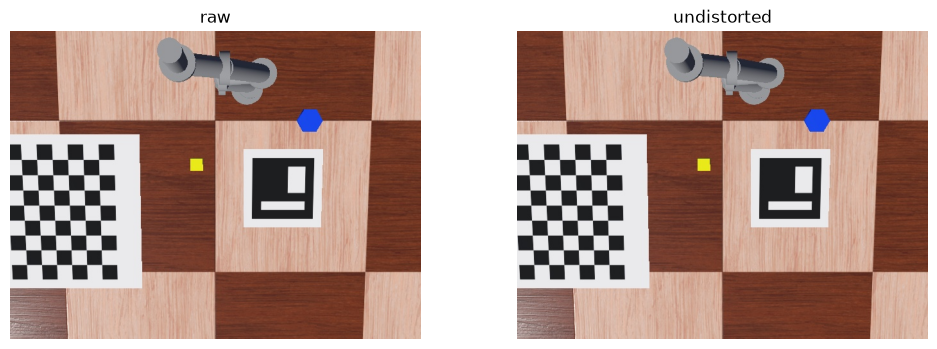

In [3]:
# ---------- 1. Capture + undistort ----------
get_snapshot() # clear old image
raw = get_snapshot()
h, w = raw.shape[:2]
assert (w, h) == calib_size, f"Image is {w}x{h} but calibration was done at {calib_size}"

# alpha=0 -> crop to valid pixels only; the new camera matrix describes the undistorted image
K_new, _ = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0)
img = cv2.undistort(raw, K, dist, None, K_new)
# From here on: use K_new and ZERO distortion.

plt.figure(figsize=(12, 4))
plt.subplot(121); plt.imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); plt.title("raw"); plt.axis("off")
plt.subplot(122); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("undistorted"); plt.axis("off")
plt.show()

In [4]:
# ---------- 2. ArUco marker pose ----------
detector = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(ARUCO_DICT),
                                   cv2.aruco.DetectorParameters())
corners, ids, _ = detector.detectMarkers(img)
if ids is None or MARKER_ID not in ids.flatten():
    raise RuntimeError(f"Marker {MARKER_ID} not found (saw: {None if ids is None else ids.flatten().tolist()})")

idx = int(np.where(ids.flatten() == MARKER_ID)[0][0])
img_pts = corners[idx].reshape(4, 2).astype(np.float32) # TL, TR, BR, BL

half = MARKER_WIDTH / 2
obj_pts = np.array([[-half,  half, 0],
                    [ half,  half, 0],
                    [ half, -half, 0],
                    [-half, -half, 0]], np.float32)

ok, rvec, tvec = cv2.solvePnP(obj_pts, img_pts, K_new, None, flags=cv2.SOLVEPNP_IPPE_SQUARE)
assert ok, "solvePnP failed"
R = cv2.Rodrigues(rvec)[0]
t = tvec.ravel()
print("R =\n", R)
print("Marker distance from camera: %.3f m" % (np.linalg.norm(t)))

R =
 [[ 1.08110633e-03 -9.99956159e-01  9.30110776e-03]
 [-9.94164007e-01 -7.14040628e-05  1.07879201e-01]
 [-1.07873807e-01 -9.36345545e-03 -9.94120499e-01]]
Marker distance from camera: 0.823 m


In [5]:
# ---------- 3. Yellow object via HSV ----------
hsv  = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, np.array(HSV_LOWER, np.uint8), np.array(HSV_UPPER, np.uint8))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  np.ones((3, 3), np.uint8))

contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv2.contourArea(c) > MIN_AREA]
if not contours:
    raise RuntimeError("No yellow object found - adjust HSV_LOWER / HSV_UPPER")

cnt = max(contours, key=cv2.contourArea)
M = cv2.moments(cnt)
u, v = M["m10"] / M["m00"], M["m01"] / M["m00"]
print(f"Yellow centre in image: ({u:.1f}, {v:.1f}) px, area {cv2.contourArea(cnt):.0f} px")

Yellow centre in image: (290.0, 208.5) px, area 374 px


In [6]:
# ---------- 4. Pixel -> point on the marker plane ----------
def pixel_to_plane(uv, K, R, t, height=0.0):
    """Intersect the camera ray through pixel uv with the plane z = height in the marker frame."""
    d = np.linalg.inv(K) @ np.array([uv[0], uv[1], 1.0])    # ray direction (camera frame)
    n = R[:, 2]                                             # marker z-axis (camera frame)
    s = (height + n @ t) / (n @ d)                          # ray scale at the intersection
    return R.T @ (s * d - t)                                # point in the marker frame

X, Y, Z = pixel_to_plane((u, v), K_new, R, t)
print(f"Yellow object centre in marker frame: X = {X:.3f} m, Y = {Y:.3f} m (Z = {Z:.3f} m)")

Yellow object centre in marker frame: X = 0.039 m, Y = 0.142 m (Z = 0.000 m)


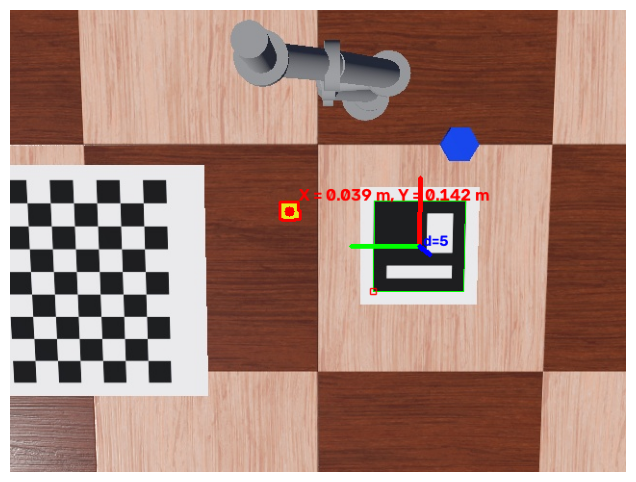

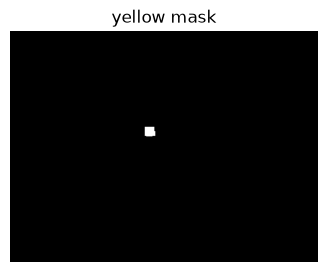

In [7]:
# ---------- 5. Visualise ----------
vis = img.copy()
cv2.aruco.drawDetectedMarkers(vis, [corners[idx]], ids[idx:idx + 1])
cv2.drawFrameAxes(vis, K_new, None, rvec, tvec, MARKER_WIDTH * 0.75)
cv2.drawContours(vis, [cnt], -1, (0, 0, 255), 2)
cv2.circle(vis, (int(round(u)), int(round(v))), 5, (0, 0, 255), -1)
cv2.putText(vis, f"X = {X:.3f} m, Y = {Y:.3f} m", (int(u) + 10, max(int(v) - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
plt.figure(figsize=(5, 3)); plt.imshow(mask, cmap="gray"); plt.title("yellow mask"); plt.axis("off"); plt.show()

## Global and robot coordinates

The marker and robot poses come from the scene REST API (Webots world frame). The yellow object position in the marker frame from above is transformed into the world frame, then into the robot base frame.

In [8]:
# ---------- 6. Scene API config + helpers ----------
API_URL     = "http://localhost:8002"
MARKER_NODE = "ARUCO_5" # DEF name of the marker node in the Webots world
ROBOT_NODE  = "ROBOT"   # DEF name of the robot (its base) in the Webots world

# Marker frame: origin at marker centre, X right, Y up, Z out of the marker face.
MARKER_TO_NODE_R = np.eye(3)
MARKER_TO_NODE_T = np.zeros(3)

# Robot base frame (e.g. base_link) relative to the Webots robot node:
ROBOT_BASE_R = np.eye(3)
ROBOT_BASE_T = np.zeros(3)


def get_pose(name):
    r = requests.get(f"{API_URL}/objects/{name}/pose", timeout=5)
    r.raise_for_status()
    return r.json()

def pose_to_Rt(pose):
    """API pose (position + Webots axis_angle [x, y, z, angle]) -> rotation matrix, translation."""
    x, y, z, a = pose["axis_angle"]
    axis = np.array([x, y, z], float)
    axis /= np.linalg.norm(axis) or 1.0
    pos = np.asarray(pose["position"], float).ravel()
    if pos.size != 3:
        print(f"WARNING: position has {pos.size} values {pos.tolist()} - using the first 3. Full pose: {pose}")
        pos = pos[:3]
    return cv2.Rodrigues(axis * a)[0], pos

In [9]:
# ---------- 7. Yellow object in the WORLD frame ----------
R_wm, t_wm = pose_to_Rt(get_pose(MARKER_NODE)) # marker node in world
p_marker = np.array([X, Y, Z])                 # from the vision part
p_node   = MARKER_TO_NODE_R @ p_marker + MARKER_TO_NODE_T
p_world  = R_wm @ p_node + t_wm

print("Marker centre (world):", np.round(t_wm, 4), "m")
print("Yellow object (world): X = %.3f m, Y = %.3f m, Z = %.3f m" % tuple(p_world))

Marker centre (world): [-0.11 -0.11  0.  ] m
Yellow object (world): X = -0.071 m, Y = 0.032 m, Z = 0.000 m


In [10]:
# ---------- 8. Yellow object relative to the ROBOT ----------
R_wr, t_wr = pose_to_Rt(get_pose(ROBOT_NODE)) # robot node in world
R_wb = R_wr @ ROBOT_BASE_R                    # robot base frame in world
t_wb = R_wr @ ROBOT_BASE_T + t_wr

p_robot = p_world - t_wb

ROBOT_BASE_WORLD =  np.round(t_wb, 4)
print("Robot base (world):", ROBOT_BASE_WORLD, "m")
print("Yellow object in robot base frame: X = %.3f m, Y = %.3f m, Z = %.3f m" % tuple(p_robot))

Robot base (world): [ 0.05 -0.05  0.01] m
Yellow object in robot base frame: X = -0.121 m, Y = 0.082 m, Z = -0.010 m


## Pick and place

Uses the robot bridge (port 8001) like the demo script: move above the object, switch the suction on, descend (Cartesian), lift, move to the drop position, release. The pick target comes from the vision result above.

In [11]:
# ---------- 9. Pick-and-place config + robot API helpers ----------
BASE_URL = "http://localhost:8001" # FastAPI ROS 2 bridge

ORIENTATION = {"roll": 3.14, "pitch": 0.0, "yaw": 0.0} # tool pointing down
PLACE_XY = (-0.05, 0.12)     # base_link frame
HOME     = (0.0, 0.12, 0.10) # start/end pose, must be collision free

BOX_HEIGHT = 0.01 # full height of the yellow object (m)
SAFE_Z     = 0.1  # travel height above the highest target

SUCTION_SETTLE_S     = 0.8
RELEASE_SETTLE_S     = 0.5
MOVE_START_TIMEOUT_S = 3.0
MOVE_DONE_TIMEOUT_S  = 30.0


def api_get(path):
    r = requests.get(f"{BASE_URL}{path}", timeout=2)
    r.raise_for_status()
    return r.json()

def api_post(path, payload):
    r = requests.post(f"{BASE_URL}{path}", json=payload, timeout=2)
    r.raise_for_status()
    return r.json()

def is_moving():
    return api_get("/api/status").get("is_moving", False)

def move_to(x, y, z, cartesian=False):
    """Send a pose and block until the robot has started and finished moving."""
    api_post("/api/move", {"x": x, "y": y, "z": z, **ORIENTATION, "cartesian_path": cartesian})
    print(f"  move -> x={x:.3f} y={y:.3f} z={z:.3f}{' (cartesian)' if cartesian else ''}")

    t0, started = time.time(), False
    while time.time() - t0 < MOVE_START_TIMEOUT_S:
        if is_moving():
            started = True
            break
        time.sleep(0.05)
    if not started:
        time.sleep(0.3)
        return

    t0 = time.time()
    while is_moving():
        if time.time() - t0 > MOVE_DONE_TIMEOUT_S:
            raise TimeoutError("Robot did not finish moving in time")
        time.sleep(0.1)
    time.sleep(0.2)

def gripper(on):
    api_post("/api/gripper", {"on": on})
    print(f"  gripper {'ON' if on else 'OFF'}")

def object_attached():
    return api_get("/api/gripper").get("object_attached", False)

In [12]:
# ---------- 10. Targets from the vision result (base_link frame) ----------
p_pick = np.asarray(p_robot, float)

PICK_XY      = (float(p_pick[0]), float(p_pick[1]))
OBJECT_TOP_Z = BOX_HEIGHT + p_pick[2] + 0.001
PLACE_Z      = BOX_HEIGHT + p_pick[2] + 0.001

print(f"Pick  (base_link): x={PICK_XY[0]:.3f} y={PICK_XY[1]:.3f} tool z={OBJECT_TOP_Z:.3f}")
print(f"Place (base_link): x={PLACE_XY[0]:.3f} y={PLACE_XY[1]:.3f} tool z={PLACE_Z:.3f}")
print(f"Travel height z={SAFE_Z:.3f}")

Pick  (base_link): x=-0.121 y=0.082 tool z=0.001
Place (base_link): x=-0.050 y=0.120 tool z=0.001
Travel height z=0.100


In [13]:
# ---------- 11. Pick and place ----------
def pick(x, y):
    print(f"Picking at ({x:.3f}, {y:.3f})")
    move_to(x, y, SAFE_Z)
    gripper(True)
    move_to(x, y, OBJECT_TOP_Z, cartesian=True)
    time.sleep(SUCTION_SETTLE_S)
    move_to(x, y, SAFE_Z, cartesian=True)
    if not object_attached():
        gripper(False)
        raise RuntimeError("Pick failed: no object detected on the suction cup")
    print("  object attached")

def place(x, y):
    print(f"Placing at ({x:.3f}, {y:.3f})")
    move_to(x, y, SAFE_Z)
    move_to(x, y, PLACE_Z, cartesian=True)
    gripper(False)
    time.sleep(RELEASE_SETTLE_S)
    move_to(x, y, SAFE_Z, cartesian=True)
    if object_attached():
        print("  warning: presence still reports an object after release")


api_get("/api/status") # will fail if the bridge is not running
gripper(False)
move_to(*HOME)
try:
    pick(*PICK_XY)
    place(*PLACE_XY)
    move_to(*HOME)
    print("Pick and place complete")
except (RuntimeError, TimeoutError, KeyboardInterrupt) as e:
    print(f"Aborting: {e!r}")
    gripper(False)
    move_to(*HOME)

  gripper OFF
  move -> x=0.000 y=0.120 z=0.100
Picking at (-0.121, 0.082)
  move -> x=-0.121 y=0.082 z=0.100
  gripper ON
  move -> x=-0.121 y=0.082 z=0.001 (cartesian)
  move -> x=-0.121 y=0.082 z=0.100 (cartesian)
  object attached
Placing at (-0.050, 0.120)
  move -> x=-0.050 y=0.120 z=0.100
  move -> x=-0.050 y=0.120 z=0.001 (cartesian)
  gripper OFF
  move -> x=-0.050 y=0.120 z=0.100 (cartesian)
  move -> x=0.000 y=0.120 z=0.100
Pick and place complete
